
# Earthquakes as a Critical Phenomenon

Since 1956, seismologists have known that earthquake frequency and
magnitude obey the **Gutenberg-Richter law**: the number of earthquakes
at least magnitude $M$ falls off as $\log_{10} N(\geq M) = a - bM$, with
$b$ close to $1$ almost everywhere on Earth. There's no "typical"
earthquake size, from imperceptible tremors to magnitude-9 megathrusts —
just fewer and fewer of them as magnitude grows. Bak and Tang first
proposed in 1989 that this is a signature of self-organized criticality
(SOC): faults don't need a special trigger to produce a huge earthquake,
because the crust is *always* poised at a critical point.

This is the third demo in this repository's SOC series (see
`../../wildfire/` and `../../sandpile/` for the first two). It implements
the **Olami-Feder-Christensen (OFC) model** (1992) — the standard SOC
model built specifically for faults, as a grid of elastically coupled
blocks that load slowly and slip suddenly. Two things make it a
genuinely different data point from the previous two demos, not just a
re-skin:

- It is explicitly **non-conservative** — a fraction of the stress
  released in a rupture is permanently lost (radiated away), unlike the
  sandpile's exactly-conserved toppling. Whether SOC survives without
  conservation was OFC's central question, and turns out to depend on
  *how* non-conservative the model is — giving this system a real extra
  knob to explore that the other two didn't have.
- Its avalanche-size statistics translate directly into the actual
  Gutenberg-Richter law, with a b-value we can compare to the real
  Earth's.


In [1]:

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent.parent))  # -> toySystems/

import numpy as np
from IPython.display import Video, display

from common import powerlaw, spectral
from common.viz import set_style, save_fig, PALETTE, ACCENT, ACCENT2, MUTED
from earthquake.model import OFCModel
from earthquake.viz import animate_grid, show_grid

import matplotlib.pyplot as plt

set_style()

FIG_DIR = Path("../figures")
VID_DIR = Path("../videos")
DATA_DIR = Path("../data")
for d in (FIG_DIR, VID_DIR, DATA_DIR):
    d.mkdir(exist_ok=True, parents=True)

RNG_SEED = 20260912



## The model

Every site on an $L \times L$ grid holds a continuous stress $F(i,j) \in
[0, F_{th})$. Two phases, never interleaved:

1. **Load:** the tectonic plates drive the whole fault at once, so every
   site's stress rises by the same amount. Rather than simulate that
   rise in tiny increments, we jump directly to the moment the
   most-stressed site reaches failure — an exact shortcut ("extremal
   driving"), not an approximation, since nothing else happens in
   between.
2. **Rupture:** any site with $F \geq F_{th}$ slips — it drops to $0$
   and each of its neighbors gains a fraction $\alpha$ of the stress it
   released. If that pushes a neighbor over threshold too, it ruptures
   next sweep, and so on until the fault is stable again. That whole
   cascade is one earthquake.

The parameter to watch is $\alpha$. At $\alpha = 1/4$ every unit of
released stress is fully conserved (handed entirely to the four
neighbors) — mathematically identical to the sandpile's toppling rule.
Real faults don't conserve stress: some energy radiates away as seismic
waves and heat every time rock grinds against rock. Olami, Feder and
Christensen's question was whether criticality survives once you stop
assuming conservation — and, within a range, it does. (The conservative
limit $\alpha \to 1/4$ is actually a special, somewhat pathological
point: it produces rare, anomalously large, near-synchronized events
rather than a clean power law — one more reason real faults, which are
manifestly non-conservative, are a better fit to the *non*-conservative
model.) We'll see below exactly how much dissipation is too much.


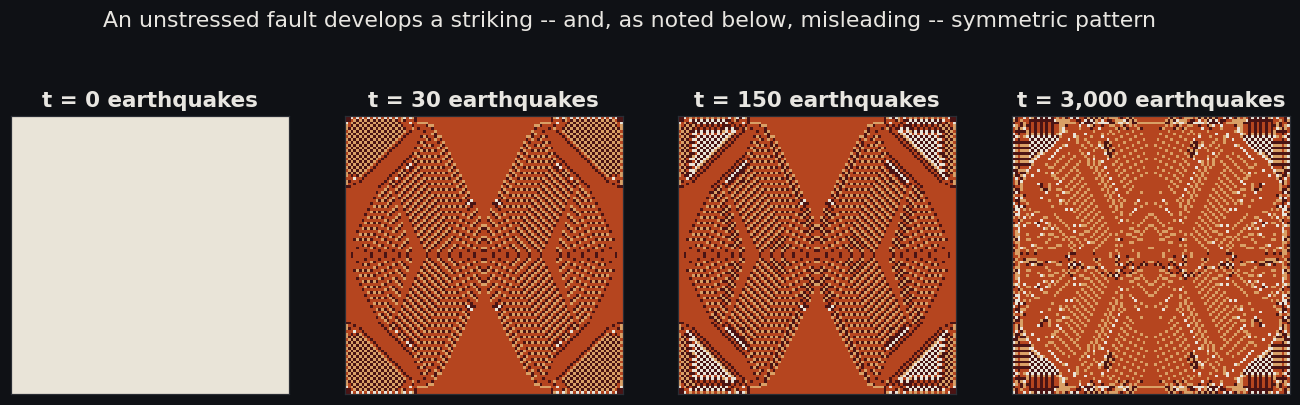

In [2]:

# start completely unstressed, so the buildup to a self-organized fault
# is visible, rather than starting already near the stationary state
model = OFCModel(L=100, alpha=0.2, seed=RNG_SEED)
model.F[:] = 0.0

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
checkpoints = [0, 30, 150, 3000]
snaps = {}
for target in checkpoints:
    while model.t < target:
        model.step()
    snaps[target] = model.render_code()

for ax, t in zip(axes, checkpoints):
    show_grid(ax, snaps[t], title=f"t = {t:,} earthquakes")

fig.suptitle("An unstressed fault develops a striking -- and, as noted below, misleading -- symmetric pattern",
             y=1.05, color="#e8e6e1")
save_fig(fig, FIG_DIR / "self_organization_snapshots.png")
plt.show()



That mirror-symmetric wave pattern is real, but it's not the generic
critical texture -- it's a known artifact of starting from an *exactly*
uniform stress ($F=0$ everywhere) with fully deterministic dynamics.
Nothing in the loading step or the toppling rule is random, so the only
source of any asymmetry is the initial condition; start perfectly
symmetric, and the whole evolution stays perfectly symmetric. Break that
symmetry -- as any real fault's heterogeneous initial stress would --
and the disordered texture we actually want shows up immediately.


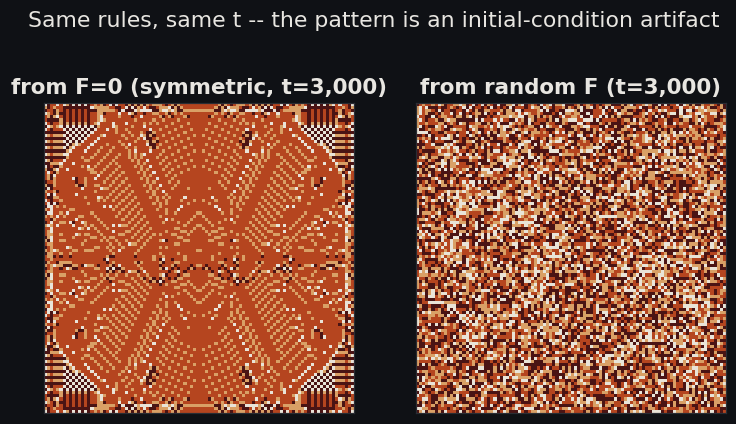

In [3]:

random_model = OFCModel(L=100, alpha=0.2, seed=RNG_SEED)  # default: random initial stress
random_model.run(3000)

fig, axes = plt.subplots(1, 2, figsize=(8, 4.2))
show_grid(axes[0], snaps[3000], title="from F=0 (symmetric, t=3,000)")
show_grid(axes[1], random_model.render_code(), title="from random F (t=3,000)")
fig.suptitle("Same rules, same t -- the pattern is an initial-condition artifact",
             y=1.03, color="#e8e6e1")
save_fig(fig, FIG_DIR / "symmetry_artifact_comparison.png")
plt.show()



## Watching it run

Most earthquakes here are microscopic — a single site slips and nothing
else happens. Every so often, a rupture finds a large connected region
that had quietly built up nearly to threshold together, and the whole
patch lets go at once (the yellow flash below).


In [4]:

vid_model = OFCModel(L=80, alpha=0.2, seed=RNG_SEED + 1)
vid_model.run(2000)  # reach the statistically stationary state first

frames, activity = vid_model.run_frames(70)
video_path = animate_grid(
    frames, VID_DIR / "steady_state_dynamics.mp4", fps=15, dpi=100,
    title="OFC model SOC: steady-state seismicity", activity=activity,
)
display(Video(str(video_path), embed=True, html_attributes="loop autoplay muted controls"))



## Anatomy of a single earthquake

One rupture spreads outward through however much of the pre-loaded
patch it can reach, then stops once the local stress drops back below
threshold everywhere.


In [5]:

av_model = OFCModel(L=80, alpha=0.2, seed=RNG_SEED + 2)
av_model.run(2000)
av_frames, av_activity = av_model.capture_avalanche(min_size=500, max_events=300_000)

print(f"captured earthquake: {av_activity.sum():,} ruptures "
      f"over {len(av_activity[av_activity > 0])} relaxation sweeps, {len(av_frames)} frames total")

av_video_path = animate_grid(
    av_frames, VID_DIR / "single_earthquake.mp4", fps=10, dpi=100,
    title="Anatomy of one earthquake", activity=av_activity,
)
display(Video(str(av_video_path), embed=True, html_attributes="loop autoplay muted controls"))


captured earthquake: 677 ruptures over 95 relaxation sweeps, 95 frames total



## Hallmark #1 — power-law distributed earthquake sizes

Simulate a few hundred thousand earthquakes and record each one's
**size** (total ruptures), **area** (distinct sites), **moment** (total
stress released — our magnitude proxy), and the global **activity**
time series for the noise spectrum.


In [6]:

%%time
sim = OFCModel(L=64, alpha=0.2, seed=RNG_SEED + 3)
result = sim.run(n_events=200_000, progress=True)

print(f"{result.n_events:,} earthquakes simulated")
print(f"mean stress (last 50k events): {result.mean_stress[-50_000:].mean():.3f}")

np.savez(DATA_DIR / "earthquake_long_run.npz",
         activity=result.activity, mean_stress=result.mean_stress,
         sizes=result.sizes, durations=result.durations,
         areas=result.areas, moments=result.moments)


simulating earthquakes:   0%|          | 0/200000 [00:00<?, ?it/s]

200,000 earthquakes simulated
mean stress (last 50k events): 0.538
CPU times: user 58.5 s, sys: 685 ms, total: 59.1 s
Wall time: 58.9 s


In [7]:

fit = powerlaw.fit_power_law(result.sizes)
print(fit)
print(f"\nfitted exponent alpha = {fit.alpha:.2f} (from xmin = {fit.xmin} upward, "
      f"{fit.n_tail:,} of {result.n_events:,} earthquakes -- "
      f"{100*fit.n_tail/result.n_events:.0f}% of the data)")
print(f"log-likelihood ratio vs. an exponential tail: {fit.loglik_ratio_exp:.1f} "
      f"(p = {fit.p_value_exp:.2g}) -> power law strongly favored")


PowerLawFit(alpha=1.882453067205345, xmin=2, ks_distance=0.011402956625755245, n_tail=65085, loglik_ratio_exp=51003.62426163789, p_value_exp=0.0)

fitted exponent alpha = 1.88 (from xmin = 2 upward, 65,085 of 200,000 earthquakes -- 33% of the data)
log-likelihood ratio vs. an exponential tail: 51003.6 (p = 0) -> power law strongly favored



Unlike the sandpile, this isn't a tail-only fit forced by curvature in
the bulk — the default settings already keep the great majority of the
data, and it's a clean fit (check the small `ks_distance` above). Every
demo in this series shows the same qualitative hallmark, but exactly how
easy it is to establish varies with the model, which is itself worth
noticing.


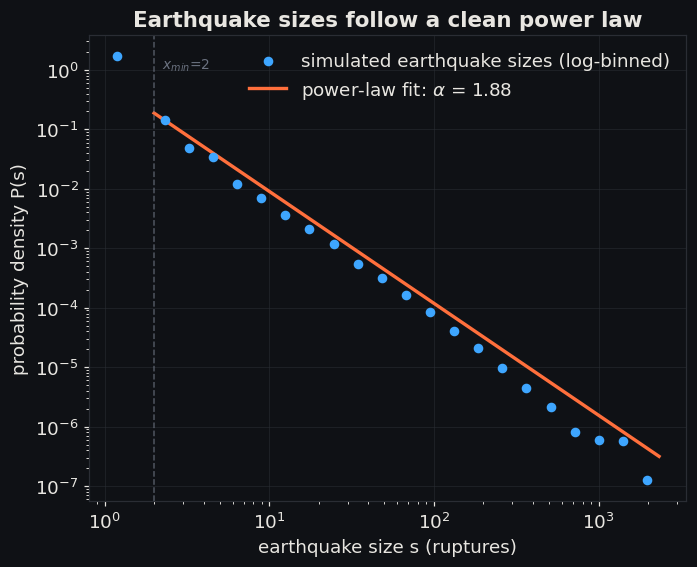

In [8]:

centers, dens = powerlaw.log_binned_histogram(result.sizes)

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(centers, dens, s=28, color=ACCENT2, zorder=3, label="simulated earthquake sizes (log-binned)")

c0 = centers[centers >= fit.xmin][0]
d0 = dens[centers >= fit.xmin][0]
xs = np.logspace(np.log10(fit.xmin), np.log10(result.sizes.max()), 50)
ax.plot(xs, d0 * (xs / c0) ** (-fit.alpha), color=ACCENT, lw=2.2,
        label=fr"power-law fit: $\alpha$ = {fit.alpha:.2f}")
ax.axvline(fit.xmin, color=MUTED, ls="--", lw=1, alpha=0.7)
ax.text(fit.xmin, dens.max(), f"  $x_{{min}}$={fit.xmin}", color=MUTED, fontsize=9, va="top")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("earthquake size s (ruptures)")
ax.set_ylabel("probability density P(s)")
ax.set_title("Earthquake sizes follow a clean power law")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "earthquake_size_powerlaw.png")
plt.show()



## The Gutenberg-Richter law

Real seismologists don't plot a size distribution this way — they define
a magnitude $M = \log_{10}(\text{moment})$ and plot $\log_{10} N(\geq M)$
against $M$ directly, since $M$ is already a log quantity. If sizes are
power-law distributed, this comes out a straight line whose (negative)
slope is the **b-value** — and real tectonic earthquakes almost
everywhere on Earth give $b \approx 1$. Let's check what our toy fault
gives.


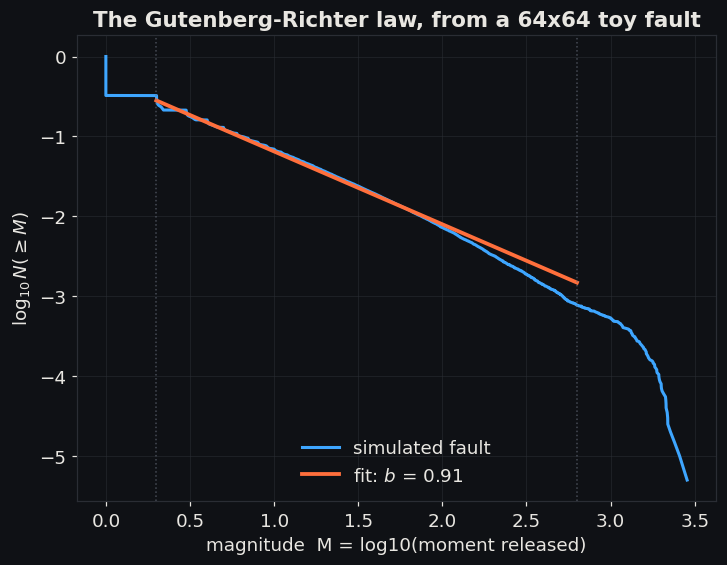

fitted b-value: 0.91  (real tectonic earthquakes: b ~ 1.0, typically 0.8-1.2)


In [9]:

M = np.log10(result.moments[result.moments > 0])
M_sorted = np.sort(M)
n = len(M_sorted)
ccdf = 1.0 - np.arange(n) / n  # fraction of events with magnitude >= M_sorted[i]

# fit the b-value over the visually linear part of the curve -- most
# "earthquakes" here are a single site (M=0, a third of all events, a
# discreteness floor rather than part of the scaling regime) and the
# largest few are always sparse and noisy, same caveat as every other
# power-law tail in this series
lo, hi = 0.3, 2.8
mask = (M_sorted >= lo) & (M_sorted <= hi) & (ccdf > 0)
b_value, intercept = np.polyfit(M_sorted[mask], np.log10(ccdf[mask]), 1)
b_value = -b_value

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.plot(M_sorted[ccdf > 0], np.log10(ccdf[ccdf > 0]), color=ACCENT2, lw=2,
        label="simulated fault")
fit_M = np.linspace(lo, hi, 20)
ax.plot(fit_M, intercept - b_value * fit_M, color=ACCENT, lw=2.5,
        label=fr"fit: $b$ = {b_value:.2f}")
ax.axvline(lo, color=MUTED, ls=":", lw=1, alpha=0.6)
ax.axvline(hi, color=MUTED, ls=":", lw=1, alpha=0.6)
ax.set_xlabel("magnitude  M = log10(moment released)")
ax.set_ylabel(r"$\log_{10} N(\geq M)$")
ax.set_title("The Gutenberg-Richter law, from a 64x64 toy fault")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "gutenberg_richter.png")
plt.show()

print(f"fitted b-value: {b_value:.2f}  (real tectonic earthquakes: b ~ 1.0, typically 0.8-1.2)")



## Does the degree of conservation matter?

The whole point of the OFC model was testing whether criticality needs
exact conservation. Let's check directly: rerun at several values of
$\alpha$ (holding everything else fixed) and see how the size
distribution's tail responds.


alpha=0.20  max size=   428  alpha_fit=2.09  R=   4163.1  -> power law


alpha=0.15  max size=    73  alpha_fit=3.59  R=  -3040.6  -> NOT power law (exponential-like)


alpha=0.10  max size=    20  alpha_fit=4.20  R=  -6125.6  -> NOT power law (exponential-like)


alpha=0.05  max size=     7  alpha_fit=5.06  R=  -5085.0  -> NOT power law (exponential-like)


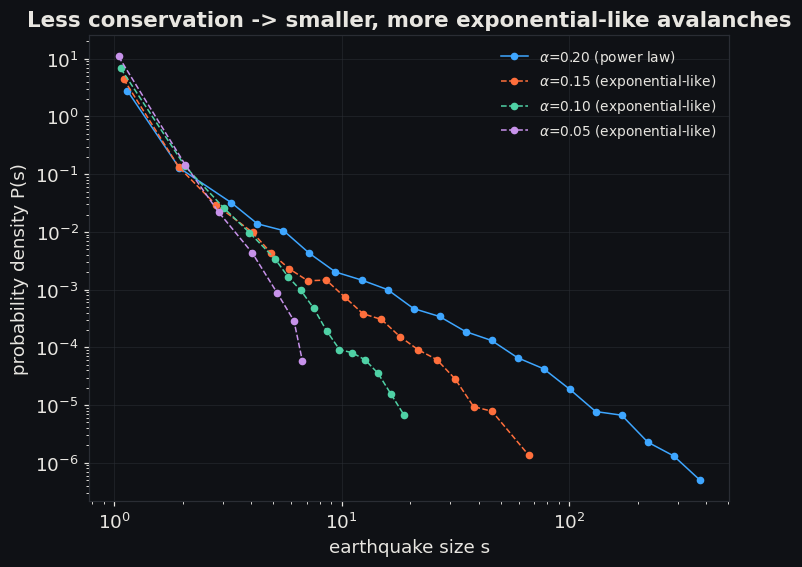

In [10]:

alphas = [0.20, 0.15, 0.10, 0.05]
alpha_results = {}
for a in alphas:
    m = OFCModel(L=64, alpha=a, seed=RNG_SEED + 10)
    r = m.run(60_000)
    fit_a = powerlaw.fit_power_law(r.sizes, min_tail_fraction=0.1)
    favors = fit_a.loglik_ratio_exp > 0 and fit_a.p_value_exp < 0.05
    alpha_results[a] = (r, fit_a, favors)
    print(f"alpha={a:.2f}  max size={r.sizes.max():6d}  alpha_fit={fit_a.alpha:.2f}  "
          f"R={fit_a.loglik_ratio_exp:9.1f}  -> {'power law' if favors else 'NOT power law (exponential-like)'}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
for a, color in zip(alphas, PALETTE):
    r, fit_a, favors = alpha_results[a]
    c, d = powerlaw.log_binned_histogram(r.sizes)
    style = "o-" if favors else "o--"
    ax.plot(c, d, style, color=color, ms=4, lw=1,
            label=fr"$\alpha$={a:.2f} ({'power law' if favors else 'exponential-like'})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("earthquake size s")
ax.set_ylabel("probability density P(s)")
ax.set_title("Less conservation -> smaller, more exponential-like avalanches")
ax.legend(frameon=False, fontsize=9)
save_fig(fig, FIG_DIR / "alpha_comparison.png")
plt.show()



At $\alpha=0.2$ the tail is a genuine, statistically confirmed power law
reaching hundreds of ruptures. Dissipate more ($\alpha = 0.1$, $0.05$)
and the largest events shrink by more than an order of magnitude, and
the likelihood-ratio test flips to favoring a plain exponential — SOC
isn't just automatic here the way it was for the sandpile. **How much**
non-conservation a system can tolerate before criticality breaks down is
itself the physically interesting question OFC raised, and it's
model-specific: there's no universal dissipation budget that works for
every SOC system.



## Hallmark #2 — 1/f-type ("colored") noise

Back to the main $\alpha=0.2$ run: take the global activity (sites
rupturing per tick, summed over the fault) and look at its power
spectrum, fitting only in the band between the low-frequency knee and
the high-frequency single-rupture floor, exactly as in the previous two
notebooks.


fitted spectral slope beta = 1.73 -> red / brown noise (beta ~ 2): a random walk, strongly autocorrelated


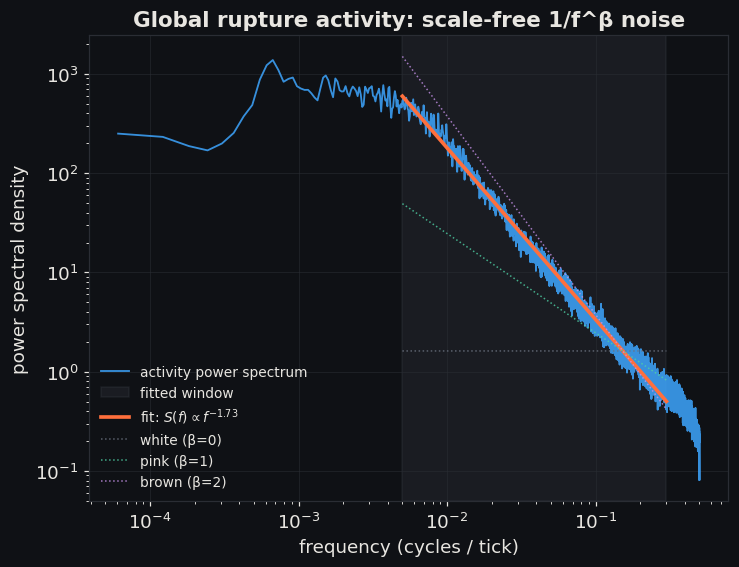

In [11]:

freqs, psd = spectral.welch_psd(result.activity)
FIT_FMIN, FIT_FMAX = 0.005, 0.3
spec_fit = spectral.fit_spectral_slope(freqs, psd, fmin=FIT_FMIN, fmax=FIT_FMAX)
print(f"fitted spectral slope beta = {spec_fit.beta:.2f} -> {spectral.classify_noise_color(spec_fit.beta)}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.loglog(freqs[1:], psd[1:], color=ACCENT2, lw=1.2, alpha=0.85, label="activity power spectrum")
ax.axvspan(FIT_FMIN, FIT_FMAX, color=MUTED, alpha=0.12, label="fitted window")

f_ref = spec_fit.freqs
scale = 10 ** spec_fit.intercept
ax.loglog(f_ref, scale * f_ref ** (-spec_fit.beta), color=ACCENT, lw=2.4,
          label=fr"fit: $S(f) \propto f^{{-{spec_fit.beta:.2f}}}$")

f_anchor = f_ref[len(f_ref) // 2]
y_anchor = scale * f_anchor ** (-spec_fit.beta)
for beta_ref, label, color in [(0, "white (β=0)", MUTED), (1, "pink (β=1)", PALETTE[2]), (2, "brown (β=2)", PALETTE[3])]:
    ax.loglog(f_ref, y_anchor * (f_ref / f_anchor) ** (-beta_ref),
              color=color, lw=1, ls=":", alpha=0.8, label=label)

ax.set_xlabel("frequency (cycles / tick)")
ax.set_ylabel("power spectral density")
ax.set_title("Global rupture activity: scale-free 1/f^β noise")
ax.legend(frameon=False, fontsize=9)
save_fig(fig, FIG_DIR / "activity_power_spectrum.png")
plt.show()



## Self-organization in action: stress needs no tuning

The mean fault stress was never set to a target — it settles on its own
and stays there, independent of the (arbitrary) initial condition.


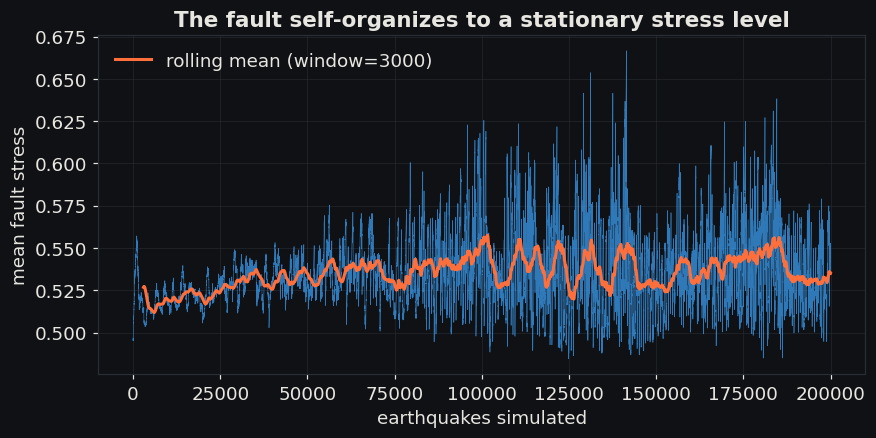

In [12]:

fig, ax = plt.subplots(figsize=(9, 4))
t = np.arange(len(result.mean_stress))
ax.plot(t, result.mean_stress, color=ACCENT2, lw=0.4, alpha=0.7)
window = 3000
rolling = np.convolve(result.mean_stress, np.ones(window) / window, mode="valid")
ax.plot(t[window - 1:], rolling, color=ACCENT, lw=2, label=f"rolling mean (window={window})")
ax.set_xlabel("earthquakes simulated")
ax.set_ylabel("mean fault stress")
ax.set_title("The fault self-organizes to a stationary stress level")
ax.legend(frameon=False)
save_fig(fig, FIG_DIR / "stress_self_organization.png")
plt.show()



## Summary dashboard


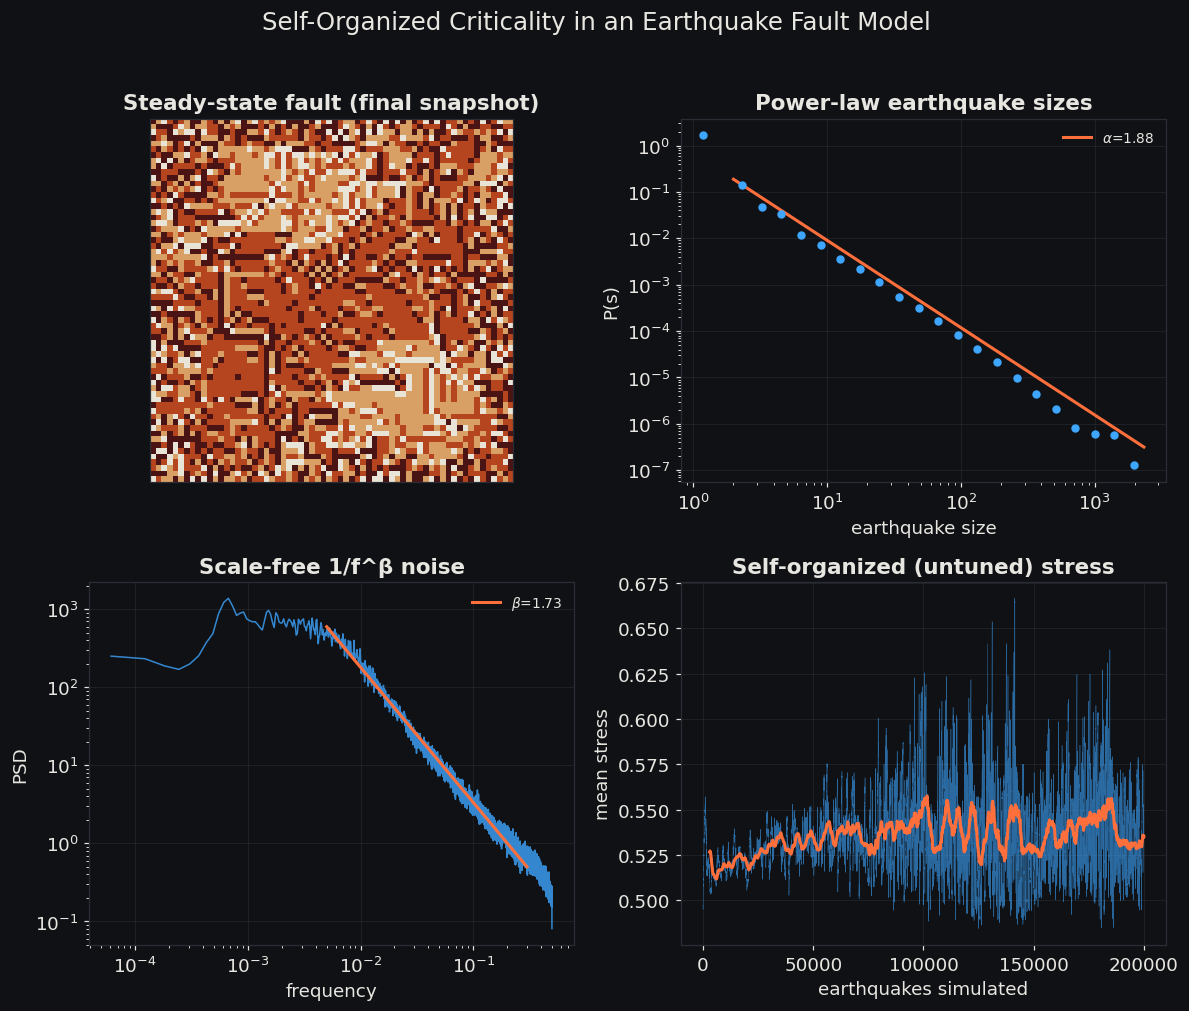

In [13]:

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

show_grid(axes[0, 0], sim.render_code(), title="Steady-state fault (final snapshot)")

ax = axes[0, 1]
ax.scatter(centers, dens, s=20, color=ACCENT2, zorder=3)
ax.plot(xs, d0 * (xs / c0) ** (-fit.alpha), color=ACCENT, lw=2,
        label=fr"$\alpha$={fit.alpha:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("earthquake size"); ax.set_ylabel("P(s)")
ax.set_title("Power-law earthquake sizes")
ax.legend(frameon=False, fontsize=9)

ax = axes[1, 0]
ax.loglog(freqs[1:], psd[1:], color=ACCENT2, lw=1, alpha=0.8)
ax.loglog(f_ref, scale * f_ref ** (-spec_fit.beta), color=ACCENT, lw=2,
          label=fr"$\beta$={spec_fit.beta:.2f}")
ax.set_xlabel("frequency"); ax.set_ylabel("PSD")
ax.set_title("Scale-free 1/f^β noise")
ax.legend(frameon=False, fontsize=9)

ax = axes[1, 1]
ax.plot(t, result.mean_stress, color=ACCENT2, lw=0.3, alpha=0.6)
ax.plot(t[window - 1:], rolling, color=ACCENT, lw=2)
ax.set_xlabel("earthquakes simulated"); ax.set_ylabel("mean stress")
ax.set_title("Self-organized (untuned) stress")

fig.suptitle("Self-Organized Criticality in an Earthquake Fault Model", fontsize=16, y=1.02)
fig.tight_layout()
save_fig(fig, FIG_DIR / "soc_dashboard.png")
plt.show()


In [14]:

from IPython.display import Markdown, display

display(Markdown(f'''
## Takeaways

- Two rules -- load the whole fault uniformly, then let one rupture run
  its course before the next load -- are enough to produce **global
  scale-invariance**, with nothing tuned to a special value, even though
  (unlike the sandpile) the dynamics are explicitly **non-conservative**.
- Earthquake sizes are **power-law distributed**
  ($\\alpha \\approx {fit.alpha:.2f}$, confirmed by a likelihood-ratio test
  against an exponential, R = {fit.loglik_ratio_exp:.0f}), and translate
  directly into a **Gutenberg-Richter law** with b-value $\\approx
  {b_value:.2f}$ -- close to the real Earth's $b \\approx 1$.
- Criticality is **not unconditional**: dissipating too much of the
  released stress ($\\alpha \\lesssim 0.1$ here) breaks the power law
  into something closer to exponential. Self-organization finds a
  critical point *within* a system's structure -- it doesn't guarantee
  one exists for every parameter choice.
- The global activity signal has a **scale-free 1/f^β spectrum**
  ($\\beta \\approx {spec_fit.beta:.2f}$), the temporal counterpart of the
  same criticality, exactly as in the wildfire and sandpile demos.
'''))



## Takeaways

- Two rules -- load the whole fault uniformly, then let one rupture run
  its course before the next load -- are enough to produce **global
  scale-invariance**, with nothing tuned to a special value, even though
  (unlike the sandpile) the dynamics are explicitly **non-conservative**.
- Earthquake sizes are **power-law distributed**
  ($\alpha \approx 1.88$, confirmed by a likelihood-ratio test
  against an exponential, R = 51004), and translate
  directly into a **Gutenberg-Richter law** with b-value $\approx
  0.91$ -- close to the real Earth's $b \approx 1$.
- Criticality is **not unconditional**: dissipating too much of the
  released stress ($\alpha \lesssim 0.1$ here) breaks the power law
  into something closer to exponential. Self-organization finds a
  critical point *within* a system's structure -- it doesn't guarantee
  one exists for every parameter choice.
- The global activity signal has a **scale-free 1/f^β spectrum**
  ($\beta \approx 1.73$), the temporal counterpart of the
  same criticality, exactly as in the wildfire and sandpile demos.



### Where this fits in `toySystems/`

- `earthquake/model.py` -- the Olami-Feder-Christensen automaton.
- `earthquake/viz.py` -- stress-grid-to-video rendering, another thin
  wrapper around `common.viz.animate_grid_with_activity`.
- Both hallmark checks reuse `common/powerlaw.py` and
  `common/spectral.py` unchanged, same as the other two demos; only the
  Gutenberg-Richter panel and the $\alpha$-sweep are bespoke to this
  system, because they're asking questions -- "does this match a named
  real-world law?", "how much dissipation can the system tolerate?" --
  that don't have a system-agnostic answer.

Three demos in, a pattern is clear: power-law event sizes and a
non-white, scale-free activity spectrum show up robustly across very
different local rules (probabilistic fire spread, exact sandpile
toppling, continuous non-conservative stress transfer). What varies
between them -- the exact exponents, whether the *whole* distribution or
just the tail is a clean power law, how sensitive the result is to the
fitting window, and now, whether criticality survives at all outside a
certain parameter range -- is exactly the kind of model-specific detail
that's easy to paper over with a single cherry-picked log-log plot, and
each notebook in this series has tried instead to show its work.
